# 2장 1강 · CNN과 사전학습 모델

## 실습 목표
1. 실제 RGB 사진을 CNN에 통과시키고, 특징 맵 한 영역의 Max Pooling을 수치로 검산합니다.
2. Scratch와 사전학습 ResNet18의 시작 가중치를 비교하고 37개 품종 출력을 구성합니다.
3. 같은 사진으로 분류기만 학습한 경우, 마지막 블록까지 학습한 경우, 전체를 학습한 경우를 비교합니다. 가중치 변화와 검증 정답 수를 근거로 방식을 선택합니다.

## 실습 환경 / 데이터
Python 3.10 이상, Jupyter, Pillow, NumPy, pandas, PyTorch와 torchvision을 사용합니다. 패키지가 없으면 새 셀에서 %pip install numpy pandas pillow torch torchvision을 실행하고 커널을 재시작하세요. PyTorch와 torchvision은 호환되는 조합이 필요합니다. CPU로 실행할 수 있습니다. torchvision의 ResNet18 기본 사전학습 가중치는 첫 실행 시 다운로드하거나 기존 캐시에서 읽습니다.

Oxford ZIP(또는 압축을 푼 폴더)을 노트북과 같은 위치에 두세요. 다른 위치에서는 DATA_SOURCE를 수정하세요. 제공본의 공식 Train JPEG가 빠져 있어 실제 사진이 있는 기존 val 736장을 수업용 후보로 사용합니다. 그중 37품종에서 각각 8장과 3장을 비복원 추출해 Train 296장과 Validation 111장을 만듭니다. 공식 Test는 이번 비교에서 사용하지 않습니다.

## 실습 준비
준비 셀은 위에서부터 실행하세요. 비교 실험의 전처리, 학습 및 평가 반복문은 제공 코드입니다. 수강생은 모델 구성, 학습 대상 선택, 측정값 검산과 해석에 집중합니다. 필수 1의 작은 CNN에는 32×32 입력을 사용하고, 품종 분류용 ResNet18에는 권장 전처리를 거친 224×224 입력을 사용합니다. 필수 2에서 Scratch 1개, 독립 과제에서 전이학습 모델 3개를 학습합니다. 독립 과제는 준비 셀만 실행한 상태에서도 시작할 수 있습니다.

In [1]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from io import BytesIO
from PIL import Image
from IPython.display import display
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
from copy import deepcopy
from time import perf_counter
from torch.utils.data import TensorDataset, DataLoader
torch.set_num_threads(min(4, torch.get_num_threads()))

PyTorch: 2.15.0+cpu
torchvision: 0.29.2+cpu


In [2]:
choices = [Path("oxford_dataset(1).zip"), Path("oxford_dataset.zip"), Path("oxford_dataset")]
DATA_SOURCE = next((path for path in choices if path.exists()), choices[0])

# 제공 코드: metadata.csv와 실제 이미지 파일이 있는지 확인합니다.
if not DATA_SOURCE.exists():
    raise FileNotFoundError("DATA_SOURCE를 실제 ZIP 또는 압축 해제 폴더 경로로 수정하세요.")
if DATA_SOURCE.is_file():
    with ZipFile(DATA_SOURCE) as zf:
        member_names = set(zf.namelist())
        meta_paths = sorted(n for n in member_names
                            if PurePosixPath(n).name == "metadata.csv" and "__MACOSX" not in n)
        if len(meta_paths) != 1:
            raise ValueError("metadata.csv가 하나 포함된 ZIP을 지정하세요.")
        parent = str(PurePosixPath(meta_paths[0]).parent)
        prefix = "" if parent == "." else parent + "/"
        metadata = pd.read_csv(BytesIO(zf.read(meta_paths[0])))
    def has_image(path):
        return prefix + str(path).replace("\\", "/") in member_names
    def load_rgb(path):
        with ZipFile(DATA_SOURCE) as zf:
            raw = zf.read(prefix + str(path).replace("\\", "/"))
        with Image.open(BytesIO(raw)) as im:
            return im.convert("RGB")
else:
    meta_paths = sorted(DATA_SOURCE.rglob("metadata.csv"))
    if len(meta_paths) != 1:
        raise ValueError("metadata.csv가 하나 포함된 데이터 폴더를 지정하세요.")
    data_root = meta_paths[0].parent
    metadata = pd.read_csv(meta_paths[0])
    def has_image(path):
        return (data_root / str(path)).is_file()
    def load_rgb(path):
        with Image.open(data_root / str(path)) as im:
            return im.convert("RGB")

available = metadata[metadata["image_path"].map(has_image)].copy()
pool_df = available[available["split"] == "val"].sort_values("image_path").reset_index(drop=True)
if pool_df.empty:
    raise ValueError("실제 파일이 있는 val 이미지가 필요합니다.")
class_table = pool_df[["label", "class_name"]].drop_duplicates().sort_values("label").reset_index(drop=True)
num_classes = len(class_table)
if class_table["label"].tolist() != list(range(num_classes)):
    raise ValueError("라벨이 0부터 클래스 수-1까지 이어지는지 확인하세요.")
if class_table["class_name"].duplicated().any():
    raise ValueError("품종 이름과 라벨의 대응을 확인하세요.")
sample_row = pool_df.iloc[0]
sample_image = load_rgb(sample_row["image_path"])
print("실제 원본 파일 수:", len(available))
print("이번 실습용 기존 Validation:", len(pool_df), "장")
print("품종 수:", num_classes, "/ 라벨 범위:", class_table["label"].min(), "~", class_table["label"].max())
print("사용 이미지:", sample_row["image_path"])
print("정답 품종:", sample_row["class_name"], "/ 원본 크기:", sample_image.size)
display(class_table)

# 제공 코드: 특징 맵 한 채널을 화면에 표시합니다.
# 보기 쉽게 해당 맵의 최솟값~최댓값을 회색 0~255로 바꾼 표시용 복사본입니다.
# 서로 다른 그림의 밝기를 그대로 비교해 특징의 중요도를 판단하지 않습니다.
def show_feature_map(feature, title):
    values = feature[0, 0].detach().cpu().numpy()
    low, high = float(values.min()), float(values.max())
    print(title, "/ 실제 크기:", values.shape, "/ min:", low, "/ max:", high)
    if high > low:
        shown = (values - low) / (high - low)
    else:
        shown = np.zeros_like(values)
    picture = Image.fromarray(np.rint(shown * 255).astype(np.uint8))
    display(picture.resize((192, 192), resample=Image.Resampling.NEAREST))

실제 원본 파일 수: 4405
이번 실습용 기존 Validation: 736 장
품종 수: 37 / 라벨 범위: 0 ~ 36
사용 이미지: images/val/00_Abyssinian/Abyssinian_1.jpg
정답 품종: Abyssinian / 원본 크기: (600, 400)


,label,class_name
0,0,Abyssinian
1,1,american_bulldog
2,2,american_pit_bull_terrier
3,3,basset_hound
4,4,beagle
5,5,Bengal
6,6,Birman
7,7,Bombay
8,8,boxer
9,9,British_Shorthair


In [3]:
# 공통 실험 조건 · 검증 원본은 매개변수 갱신에 사용하지 않습니다.
SEED = 42
EPOCHS = 2
BATCH = 16
LR = 0.01
train_parts, val_parts = [], []
for label, group in pool_df.groupby("label", sort=True):
    chosen = group.sample(n=11, replace=False, random_state=SEED + int(label))
    train_parts.append(chosen.iloc[:8])
    val_parts.append(chosen.iloc[8:])
train_rows = pd.concat(train_parts, ignore_index=True)
val_rows = pd.concat(val_parts, ignore_index=True)
assert set(train_rows.image_id).isdisjoint(val_rows.image_id)
assert set(train_rows.image_path).isdisjoint(val_rows.image_path)
transform = ResNet18_Weights.DEFAULT.transforms()

def prepare(rows):
    images = [transform(load_rgb(path)) for path in rows.image_path]
    return TensorDataset(torch.stack(images), torch.tensor(rows.label.to_numpy(), dtype=torch.long))

train_set = prepare(train_rows)
val_set = prepare(val_rows)
print("Train · Validation", len(train_set), len(val_set), "품종", num_classes)
print("Train 전체 입력", tuple(train_set.tensors[0].shape), train_set.tensors[0].dtype)
print("Validation 전체 입력", tuple(val_set.tensors[0].shape), val_set.tensors[0].dtype)
print("첫 검증 원본", val_rows.iloc[0].image_id, "실제 품종", val_rows.iloc[0].class_name)

Train · Validation 296 111 품종 37
Train 전체 입력 (296, 3, 224, 224) torch.float32
Validation 전체 입력 (111, 3, 224, 224) torch.float32
첫 검증 원본 Abyssinian_181 실제 품종 Abyssinian


In [4]:
# 제공 코드 · 네 모델에 같은 학습률, 손실, 배치 순서, 평가 규칙을 적용합니다.
def count_correct(model, dataset):
    model.eval()
    predicted = []
    with torch.no_grad():
        for images, _ in DataLoader(dataset, batch_size=BATCH):
            predicted.append(model(images).argmax(dim=1))
    predicted = torch.cat(predicted)
    correct = (predicted == dataset.tensors[1]).sum().item()
    return correct, predicted

def fit_and_measure(model, method):
    trainable = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(trainable, lr=LR, momentum=0.9)
    loss_fn = nn.CrossEntropyLoss()
    order = torch.Generator().manual_seed(SEED)
    loader = DataLoader(train_set, batch_size=BATCH, shuffle=True, generator=order)
    sample_weights = {"layer1":model.layer1[0].conv1.weight,
                      "layer4":model.layer4[0].conv1.weight, "fc":model.fc.weight}
    before = {name:p.detach().clone() for name,p in sample_weights.items()}
    losses = []
    start = perf_counter()
    for epoch in range(EPOCHS):
        model.train()
        # 고정 구간에서는 BatchNorm의 누적 평균·분산도 바뀌지 않게 합니다.
        if method in ("feature", "partial"):
            model.eval()
            model.fc.train()
            if method == "partial":
                model.layer4.train()
        total_loss = 0.0
        for images, labels in loader:
            opt.zero_grad()
            scores = model(images)
            loss = loss_fn(scores, labels)
            loss.backward()
            opt.step()
            total_loss += loss.item() * len(labels)
        losses.append(total_loss / len(train_set))
    seconds = perf_counter() - start
    train_ok, _ = count_correct(model, train_set)
    val_ok, pred = count_correct(model, val_set)
    record = {"방식":method, "손실1":round(losses[0],4), "손실2":round(losses[-1],4),
              "Train정답":train_ok, "Val정답":val_ok,
              "Train(%)":round(100*train_ok/len(train_set),2),
              "Val(%)":round(100*val_ok/len(val_set),2), "학습초":round(seconds,1)}
    for name, p in sample_weights.items():
        record[name+" 변화"] = (p.detach()-before[name]).abs().max().item()
    return record, pred

## 필수 1. 실제 이미지로 합성곱·풀링 결과 확인

**배경**  
교안의 무작위 입력 대신 실제 동물 이미지를 사용합니다. 모델을 학습하기 전에 각 레이어가 데이터의 구조를 어떻게 바꾸는지 확인하려고 합니다.

**요구사항**
1. **1-1:** 준비된 `sample_image`를 표시하고 `Resize((32,32)) → ToTensor()`를 적용한 뒤 `unsqueeze(0)`으로 배치 차원을 추가하세요. 원본·32×32 이미지와 입력 shape·dtype을 확인하세요.
2. **1-2:** 아래 구조를 구성하고 실제 입력에 적용하세요. 초기화 직전에 제공 코드 `torch.manual_seed(42)`를 실행하세요. 각 단계의 shape를 출력하고 `show_feature_map`으로 첫 채널을 표시하세요.
   - `Conv2d(3,8,kernel_size=3,padding=1)` → `torch.relu`
   - `MaxPool2d(kernel_size=2)`
   - `Conv2d(8,16,kernel_size=3,padding=1)` → `torch.relu`
3. **1-3:** 첫 번째 합성곱·ReLU 결과의 첫 채널에서 왼쪽 위 2×2 영역을 출력하세요. 이 영역의 최댓값과 풀링 결과의 첫 값을 비교하세요. 아래 위치 선택 코드를 활용하세요.
   - 영역: `feature1[0,0,:2,:2]`
   - 풀링 결과의 첫 값: `feature2[0,0,0,0]`
4. **1-4:** 출력 채널 수가 3→8→16으로 바뀌는 이유, 풀링의 장점과 정보 손실, 레이어 깊이와 특징의 관계를 설명하세요. 이번 특징 맵을 '동물의 눈이나 품종을 학습한 결과'라고 해석해도 되는지도 설명하세요.

**제출 결과**: 실제 이미지와 입력 구조, 단계별 특징 맵·shape, 작은 영역의 풀링 값 비교, 문항별 해석.

원본 이미지: images/val/00_Abyssinian/Abyssinian_1.jpg / 품종: Abyssinian / 크기(W,H): (600, 400) / 모드: RGB


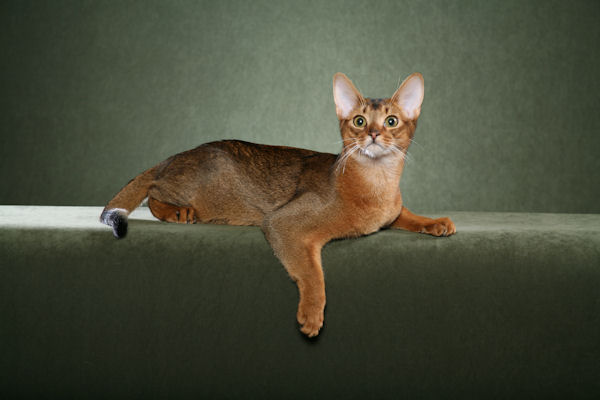

32×32 이미지 (확대 표시): (32, 32)


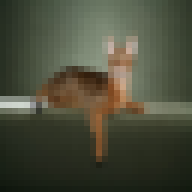

ToTensor 결과 shape: (3, 32, 32)
입력 x shape: (1, 3, 32, 32) / dtype: torch.float32
입력 값 범위: min = 0.051 / max = 0.8392


In [5]:
# 1-1. 요구사항에 맞게 코드를 작성하세요.
print("원본 이미지:", sample_row["image_path"], "/ 품종:", sample_row["class_name"],
      "/ 크기(W,H):", sample_image.size, "/ 모드:", sample_image.mode)
display(sample_image)

small_transform = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor()])
small_picture = transforms.Resize((32, 32))(sample_image)          # 화면 확인용 32×32 사진
x = small_transform(sample_image).unsqueeze(0)                     # (C,H,W) → (N,C,H,W)

print("32×32 이미지 (확대 표시):", small_picture.size)
display(small_picture.resize((192, 192), resample=Image.Resampling.NEAREST))
print("ToTensor 결과 shape:", tuple(small_transform(sample_image).shape))
print("입력 x shape:", tuple(x.shape), "/ dtype:", x.dtype)
print("입력 값 범위: min =", round(x.min().item(), 4), "/ max =", round(x.max().item(), 4))


입력           : (1, 3, 32, 32)
Conv1 + ReLU   : (1, 8, 32, 32)
MaxPool        : (1, 8, 16, 16)
Conv2 + ReLU   : (1, 16, 16, 16)
feature1 (Conv1+ReLU) 첫 채널 / 실제 크기: (32, 32) / min: 0.06535939872264862 / max: 0.6090406179428101


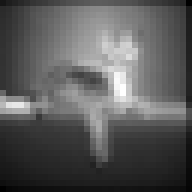

feature2 (MaxPool) 첫 채널 / 실제 크기: (16, 16) / min: 0.1031605675816536 / max: 0.6090406179428101


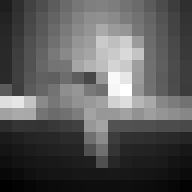

feature3 (Conv2+ReLU) 첫 채널 / 실제 크기: (16, 16) / min: 0.015023298561573029 / max: 0.1851271092891693


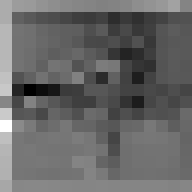

In [6]:
# 1-2. 요구사항에 맞게 코드를 작성하세요.
torch.manual_seed(42)
conv1 = nn.Conv2d(3, 8, kernel_size=3, padding=1)
pool = nn.MaxPool2d(kernel_size=2)
conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)

with torch.no_grad():
    feature1 = torch.relu(conv1(x))      # 합성곱1 + ReLU
    feature2 = pool(feature1)            # Max Pooling
    feature3 = torch.relu(conv2(feature2))  # 합성곱2 + ReLU

print("입력           :", tuple(x.shape))
print("Conv1 + ReLU   :", tuple(feature1.shape))
print("MaxPool        :", tuple(feature2.shape))
print("Conv2 + ReLU   :", tuple(feature3.shape))

show_feature_map(feature1, "feature1 (Conv1+ReLU) 첫 채널")
show_feature_map(feature2, "feature2 (MaxPool) 첫 채널")
show_feature_map(feature3, "feature3 (Conv2+ReLU) 첫 채널")


In [7]:
# 1-3. 요구사항에 맞게 코드를 작성하세요.
region = feature1[0, 0, :2, :2]
region_max = region.max().item()
pooled_first = feature2[0, 0, 0, 0].item()

print("feature1 첫 채널 왼쪽 위 2×2 영역:")
print(region)
print("영역 최댓값          :", region_max)
print("풀링 결과의 첫 값    :", pooled_first)
print("두 값이 같은가?      :", region_max == pooled_first)

# 추가 검산: 모든 채널·위치에서 2×2 최댓값이 풀링 결과와 같은지 확인
manual_pool = feature1.unfold(2, 2, 2).unfold(3, 2, 2).amax(dim=(-1, -2))
print("전체 위치 검산 일치  :", torch.equal(manual_pool, feature2))


feature1 첫 채널 왼쪽 위 2×2 영역:
tensor([[0.1121, 0.1286],
        [0.1566, 0.1633]])
영역 최댓값          : 0.1633060723543167
풀링 결과의 첫 값    : 0.1633060723543167
두 값이 같은가?      : True
전체 위치 검산 일치  : True


### 문항별 해석 작성

**1-1 답변:** 사용한 사진은 `images/val/00_Abyssinian/Abyssinian_1.jpg`(Abyssinian, 원본 600×400, RGB)입니다. `Resize((32,32))`는 가로·세로 비율을 무시하고 32×32로 줄이므로 고양이 형태가 뭉개지고 약간 눌려 보입니다. `ToTensor()` 결과는 (3, 32, 32)이고 `unsqueeze(0)` 후 입력 `x`는 **(1, 3, 32, 32), torch.float32**입니다. 각 축은 (배치 N=1, 채널 C=RGB 3, 높이 32, 너비 32)이며, ToTensor가 0~255 정수를 0~1 실수로 바꿔 값 범위가 0.051~0.839입니다.

**1-2 답변:** 시드 42로 초기화한 뒤 shape 변화는 다음과 같습니다.
- 입력 (1, 3, 32, 32) → Conv1+ReLU **(1, 8, 32, 32)**: padding=1, 3×3 커널이라 공간 크기는 유지되고 채널이 3→8로 바뀝니다.
- MaxPool **(1, 8, 16, 16)**: 2×2 창, stride 2로 높이·너비가 절반이 되고 채널 수는 그대로입니다.
- Conv2+ReLU **(1, 16, 16, 16)**: 공간 크기는 유지되고 채널이 8→16이 됩니다.

첫 채널의 값 범위는 feature1 0.065~0.609, feature2 0.103~0.609(최댓값 그대로 유지, 최솟값은 커짐), feature3 0.015~0.185입니다. 표시된 그림은 각 맵을 자체 min~max로 정규화한 것이므로 맵끼리 밝기를 직접 비교하면 안 됩니다.

**1-3 답변:** `feature1[0,0,:2,:2]` = [[0.1121, 0.1286], [0.1566, 0.1633]]입니다. 이 영역의 최댓값은 **0.16330607**이고 `feature2[0,0,0,0]`도 **0.16330607**로 정확히 같습니다(`==` → True). Max Pooling은 2×2 창의 가장 큰 값 하나만 남기는 연산임을 수치로 확인했습니다. 추가로 `unfold`로 모든 채널·위치의 2×2 최댓값을 직접 계산해 `feature2`와 비교했고 전체가 일치(True)했습니다.

**1-4 답변:**
- **채널 3→8→16:** 입력 채널 3은 RGB입니다. 이후 채널 수는 레이어가 가진 필터(커널)의 개수이며, 필터마다 서로 다른 패턴에 반응하는 특징 맵을 하나씩 만듭니다. 풀링으로 공간 해상도를 줄이는 대신 채널을 늘려 위치당 더 다양한 특징을 표현하게 하는 것이 일반적인 설계입니다.
- **풀링의 장점과 손실:** 특징 맵 크기가 1/4(32×32→16×16)로 줄어 계산량과 메모리가 줄고, 작은 위치 이동에 덜 민감해지며, 다음 층의 수용 영역이 넓어집니다. 대신 2×2 안의 나머지 세 값(예: 0.1121, 0.1286, 0.1566)과 최댓값이 창 안 어디에 있었는지 하는 위치 정보가 사라집니다.
- **깊이와 특징:** 얕은 층은 좁은 영역의 엣지·색 대비 같은 단순한 패턴을, 깊은 층은 앞 층의 특징을 조합해 넓은 영역의 복잡한 패턴(질감→부위→물체)을 표현하는 경향이 있습니다.
- **'눈이나 품종을 학습한 결과'로 해석해도 되는가:** **아닙니다.** 이 가중치는 `torch.manual_seed(42)`로 만든 무작위 초기값이고 한 번도 학습하지 않았습니다. 특징 맵에 윤곽이 보이는 이유는 무작위 필터도 입력 밝기 구조를 그대로 따라가기 때문이지, 눈이나 품종 정보를 배운 결과가 아닙니다. 게다가 32×32로 줄인 사진에서는 눈 같은 세부도 거의 남아 있지 않습니다.

## 필수 2. 초기 가중치 비교와 Scratch 기준 모델 학습

1. **2-1** Scratch와 사전학습 ResNet18을 각각 생성하고 기존 fc와 실제 Oxford 품종 수를 출력하세요. 두 모델의 첫 합성곱 가중치가 같은지 확인하세요.
2. **2-2** 두 모델의 fc를 512개 특징에서 37개 품종 점수를 내도록 교체하세요. 같은 초기 분류기를 사용하고 같은 검증 사진 한 장을 각 모델에 넣어 출력 모양, 첫 세 점수, 최고 점수의 품종 번호를 확인하세요.
3. **2-3** 모델 전체와 분류기의 파라미터 수를 확인하세요. 제공 함수로 Scratch를 2에포크 학습해 에포크별 손실, 최종 Train·Validation 정답 수와 정확도를 출력하세요. 정답 수를 분모와 함께 검산하세요.
4. **2-4** 구조·파라미터 수가 같은데 초기 점수가 다른 이유, 분류기 교체가 필요한 이유, 학습 전 한 장의 점수로 두 방식의 성능을 평가할 수 있는지 설명하세요.

In [ ]:
# 2-1. 요구사항에 맞게 코드를 작성하세요.
torch.manual_seed(SEED)
scratch_model = resnet18(weights=None)                          # 무작위 초기화
pretrained_model = resnet18(weights=ResNet18_Weights.DEFAULT)   # ImageNet 사전학습

print("Scratch 기존 fc   :", scratch_model.fc)
print("Pretrained 기존 fc:", pretrained_model.fc)
print("실제 Oxford 품종 수:", num_classes)

w_s = scratch_model.conv1.weight
w_p = pretrained_model.conv1.weight
print("첫 합성곱 가중치 shape:", tuple(w_s.shape), tuple(w_p.shape))
print("첫 합성곱 가중치가 같은가?:", torch.equal(w_s, w_p))
print("Scratch    conv1 평균/표준편차: %.5f / %.5f" % (w_s.mean().item(), w_s.std().item()))
print("Pretrained conv1 평균/표준편차: %.5f / %.5f" % (w_p.mean().item(), w_p.std().item()))
print("두 가중치 최대 절대 차이:", (w_s - w_p).abs().max().item())

Scratch 기존 fc   : Linear(in_features=512, out_features=1000, bias=True)
Pretrained 기존 fc: Linear(in_features=512, out_features=1000, bias=True)
실제 Oxford 품종 수: 37
첫 합성곱 가중치 shape: (64, 3, 7, 7) (64, 3, 7, 7)
첫 합성곱 가중치가 같은가?: False
Scratch    conv1 평균/표준편차: -0.00004 / 0.02502
Pretrained conv1 평균/표준편차: 0.00003 / 0.12970
두 가중치 최대 절대 차이: 1.034892201423645


In [9]:
# 2-2. 요구사항에 맞게 코드를 작성하세요.
torch.manual_seed(SEED)
new_fc = nn.Linear(scratch_model.fc.in_features, num_classes)   # 512 → 37
scratch_model.fc = deepcopy(new_fc)
pretrained_model.fc = deepcopy(new_fc)
print("교체된 fc:", scratch_model.fc, "/", pretrained_model.fc)
print("두 분류기 초기 가중치가 같은가?:",
      torch.equal(scratch_model.fc.weight, pretrained_model.fc.weight)
      and torch.equal(scratch_model.fc.bias, pretrained_model.fc.bias))

image0, label0 = val_set[0]
batch0 = image0.unsqueeze(0)
print("검증 사진:", val_rows.iloc[0].image_id, "/ 실제 품종:", val_rows.iloc[0].class_name, "(라벨", label0.item(), ")")
for name, model in [("Scratch", scratch_model), ("Pretrained", pretrained_model)]:
    model.eval()
    with torch.no_grad():
        scores = model(batch0)
    top = scores.argmax(dim=1).item()
    print(f"{name:10s} 출력 shape: {tuple(scores.shape)} / 첫 세 점수: {scores[0,:3].numpy().round(4)} "
          f"/ 최고 점수 품종 번호: {top} ({class_table.class_name[top]})")


교체된 fc: Linear(in_features=512, out_features=37, bias=True) / Linear(in_features=512, out_features=37, bias=True)
두 분류기 초기 가중치가 같은가?: True
검증 사진: Abyssinian_181 / 실제 품종: Abyssinian (라벨 0 )
Scratch    출력 shape: (1, 37) / 첫 세 점수: [-0.5278 -0.041  -0.3389] / 최고 점수 품종 번호: 9 (British_Shorthair)
Pretrained 출력 shape: (1, 37) / 첫 세 점수: [-0.2376  0.8195  0.3928] / 최고 점수 품종 번호: 16 (havanese)


In [10]:
# 2-3. 요구사항에 맞게 코드를 작성하세요.
def count_params(module):
    return sum(p.numel() for p in module.parameters())

print("Scratch 전체 파라미터  :", f"{count_params(scratch_model):,}")
print("Pretrained 전체 파라미터:", f"{count_params(pretrained_model):,}")
print("분류기(fc) 파라미터     :", f"{count_params(scratch_model.fc):,}", "= 512×37 + 37 =", 512*37 + 37)

scratch_record, scratch_pred = fit_and_measure(scratch_model, "scratch")
print("\n에포크별 손실:", scratch_record["손실1"], "→", scratch_record["손실2"])
print("Train 정답:", scratch_record["Train정답"], "/", len(train_set), "=", scratch_record["Train(%)"], "%")
print("Val   정답:", scratch_record["Val정답"], "/", len(val_set), "=", scratch_record["Val(%)"], "%")

# 검산: 예측을 직접 다시 세어 분모와 함께 확인
_, train_pred_check = count_correct(scratch_model, train_set)
recount_train = (train_pred_check == train_set.tensors[1]).sum().item()
recount_val = (scratch_pred == val_set.tensors[1]).sum().item()
print("검산 Train:", recount_train, "/", len(train_set), "=", round(100*recount_train/len(train_set), 2), "%")
print("검산 Val  :", recount_val, "/", len(val_set), "=", round(100*recount_val/len(val_set), 2), "%")
print("Val 예측에 등장한 서로 다른 품종 수:", scratch_pred.unique().numel())
display(pd.DataFrame([scratch_record]))


Scratch 전체 파라미터  : 11,195,493
Pretrained 전체 파라미터: 11,195,493
분류기(fc) 파라미터     : 18,981 = 512×37 + 37 = 18981

에포크별 손실: 3.994 → 3.9774
Train 정답: 11 / 296 = 3.72 %
Val   정답: 5 / 111 = 4.5 %
검산 Train: 11 / 296 = 3.72 %
검산 Val  : 5 / 111 = 4.5 %
Val 예측에 등장한 서로 다른 품종 수: 4


,방식,손실1,손실2,Train정답,Val정답,Train(%),Val(%),학습초,layer1 변화,layer4 변화,fc 변화
0,scratch,3.994,3.9774,11,5,3.72,4.5,28.3,0.027007,0.003729,0.034938


### 문항별 해석 작성

**2-1 답변:** 두 모델의 기존 fc는 모두 `Linear(512 → 1000)`으로 ImageNet 1,000개 클래스용이고, 실제 Oxford 품종 수는 **37**입니다. 첫 합성곱 `conv1.weight`는 둘 다 (64, 3, 7, 7)로 모양은 같지만 **값은 다릅니다(`torch.equal` → False)**. Scratch는 평균 -0.00004, 표준편차 0.025의 작은 무작위 값(Kaiming 초기화)이고, 사전학습 모델은 표준편차 0.130으로 ImageNet 학습을 거쳐 커진 값입니다. 두 가중치의 최대 절대 차이는 1.035입니다.

**2-2 답변:** 시드 42로 `Linear(512 → 37)` 하나를 만들고 `deepcopy`로 두 모델에 같은 초기 분류기를 넣었습니다(가중치 동일 확인 True). 같은 검증 사진 `Abyssinian_181`(정답 라벨 0)을 넣으면 출력 shape는 둘 다 **(1, 37)**입니다.
- Scratch: 첫 세 점수 [-0.5278, -0.0410, -0.3389], 최고 점수 품종 **9 (British_Shorthair)**
- Pretrained: 첫 세 점수 [-0.2376, 0.8195, 0.3928], 최고 점수 품종 **16 (havanese)**

분류기가 같아도 그 앞의 백본이 넘겨주는 512차원 특징이 다르기 때문에 점수가 달라집니다. 두 모델 모두 정답(0)을 맞히지 못했습니다.

**2-3 답변:** 전체 파라미터는 두 모델 모두 **11,195,493개**이고, 분류기는 **18,981개 (= 512×37 + 37)**입니다. Scratch를 2에포크 학습하면 손실은 **3.9940 → 3.9774**로 거의 줄지 않았고, 이는 무작위 추측 수준인 ln(37) ≈ 3.61보다도 높습니다. 최종 결과는 **Train 11/296 = 3.72%**, **Validation 5/111 = 4.50%**입니다. 예측을 직접 다시 세어도 11/296, 5/111로 같았습니다. 무작위 추측의 기대값(1/37 ≈ 2.7%, Val 약 3장)과 큰 차이가 없고, Validation 예측도 4개 품종에만 몰려 있어 사실상 학습되지 않았습니다.

**2-4 답변:**
- **같은 구조에서 초기 점수가 다른 이유:** 구조와 파라미터 수는 연산의 모양만 정합니다. 출력은 가중치 값으로 결정되는데, Scratch는 무작위 값이고 사전학습 모델은 ImageNet에서 학습한 값이라 같은 사진에서도 512차원 특징이 다르고, 같은 fc를 지나도 점수가 달라집니다.
- **분류기 교체가 필요한 이유:** 기존 fc는 ImageNet 1,000개 클래스에 대한 점수를 내므로 Oxford 37품종과 열 개수도, 각 열의 의미도 맞지 않습니다. 512→37로 바꿔야 각 출력 열이 Oxford 라벨 0~36에 대응하고 CrossEntropyLoss로 학습할 수 있습니다.
- **학습 전 한 장의 점수로 성능을 평가할 수 있는가:** **없습니다.** 새 fc가 무작위라 두 모델 모두 Oxford 기준으로는 아직 의미 없는 점수를 냅니다. 또 사진 한 장의 맞음/틀림은 표본 1개라 우연에 크게 좌우됩니다. 성능은 학습을 거친 뒤 여러 장의 검증 세트에서 정답 수로 비교해야 하며, 실제로 과제 1에서 학습한 뒤에야 큰 차이가 드러났습니다.

## 과제 1. 어느 층까지 학습할지 실제 검증 결과로 선택하기 · 필수 수준

준비 셀의 데이터와 학습·평가 함수를 사용합니다. 세 방식 모두 같은 시작 모델의 독립된 복사본을 사용하세요.

1. **3-1** 실제 사전학습 ResNet18을 불러와 37개 품종 분류기를 연결하세요. 분류기의 초기값은 시드 42로 고정하고 전체 파라미터 수를 출력하세요.
2. **3-2** feature는 fc, partial은 layer4와 fc, full은 전체 파라미터를 학습 대상으로 지정하세요. 방식별 전체 학습 대상 수·비율과 layer1, layer4, fc의 학습 대상 수를 표로 비교하세요. 각 방식의 모델을 fit_and_measure로 실제 학습하세요.
3. **3-3** 방식별 손실, 최종 Train·Validation 정답 수와 정확도, 학습 시간, 세 대표 가중치의 최대 변화량을 표로 비교하세요. 검증 사진 한 장에서 실제 품종과 세 모델의 예측을 대조하세요. 한 장의 정답 여부와 전체 순위가 같은 질문인지 설명하세요.
4. **3-4** 이 표본에서 어떤 방식을 선택할지 검증 정답 수, 학습 대상 수, 학습 비용을 인용해 설명하세요. Train과 Validation 차이 및 소표본·짧은 학습의 한계도 적으세요.

**실행 조건**　각 방식에서 시드, 입력 사진, 입력 순서, 새 fc 시작값, 학습률, 에포크 수를 맞춥니다. 한 방식에서 학습한 가중치를 다음 방식의 출발점으로 사용하지 마세요.

In [11]:
# 3-1. 문제의 요구사항에 맞게 작성하세요.
base_model = resnet18(weights=ResNet18_Weights.DEFAULT)
torch.manual_seed(SEED)
base_model.fc = nn.Linear(base_model.fc.in_features, num_classes)
print("새 분류기:", base_model.fc)
print("전체 파라미터 수:", f"{sum(p.numel() for p in base_model.parameters()):,}")
base_fc_weight = base_model.fc.weight.detach().clone()   # 세 방식 공통 시작값 확인용


새 분류기: Linear(in_features=512, out_features=37, bias=True)
전체 파라미터 수: 11,195,493


In [12]:
# 3-2. 문제의 요구사항에 맞게 작성하세요.
def make_variant(method):
    model = deepcopy(base_model)          # 매번 같은 시작 모델의 독립 복사본
    for p in model.parameters():
        p.requires_grad = (method == "full")
    if method in ("feature", "partial"):
        for p in model.fc.parameters():
            p.requires_grad = True
    if method == "partial":
        for p in model.layer4.parameters():
            p.requires_grad = True
    return model

def n_trainable(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)

methods = ["feature", "partial", "full"]
variants = {m: make_variant(m) for m in methods}
total_params = sum(p.numel() for p in base_model.parameters())
target_table = pd.DataFrame([
    {"방식": m,
     "학습 대상 수": n_trainable(model),
     "비율(%)": round(100 * n_trainable(model) / total_params, 2),
     "layer1": n_trainable(model.layer1),
     "layer4": n_trainable(model.layer4),
     "fc": n_trainable(model.fc)}
    for m, model in variants.items()])
display(target_table)

for m, model in variants.items():
    assert torch.equal(model.fc.weight, base_fc_weight), "fc 시작값이 다릅니다"

results, predictions = {}, {}
for m in methods:
    results[m], predictions[m] = fit_and_measure(variants[m], m)
    print(m, "학습 완료:", results[m]["학습초"], "초")


,방식,학습 대상 수,비율(%),layer1,layer4,fc
0,feature,18981,0.17,0,0,18981
1,partial,8412709,75.14,0,8393728,18981
2,full,11195493,100.00,147968,8393728,18981


feature 학습 완료: 10.6 초
partial 학습 완료: 15.3 초
full 학습 완료: 26.9 초


,손실1,손실2,Train정답,Val정답,Train(%),Val(%),학습초,layer1 변화,layer4 변화,fc 변화
방식,,,,,,,,,,
scratch,3.9940,3.9774,11,5,3.72,4.50,28.3,0.027007,0.003729,0.034938
feature,3.1889,0.8757,266,81,89.86,72.97,10.6,0.000000,0.000000,0.206863
partial,3.1950,0.5952,295,84,99.66,75.68,15.3,0.000000,0.012068,0.130130
full,3.2212,0.6900,286,69,96.62,62.16,26.9,0.015177,0.011928,0.120800


검증 사진: Abyssinian_181 / 실제 품종: Abyssinian (라벨 0)


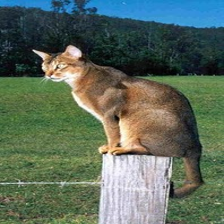

,방식,예측 번호,예측 품종,정답?
0,scratch,7,Bombay,False
1,feature,0,Abyssinian,True
2,partial,0,Abyssinian,True
3,full,0,Abyssinian,True


In [13]:
# 3-3. 문제의 요구사항에 맞게 작성하세요.
compare = pd.DataFrame([scratch_record] + [results[m] for m in methods]).set_index("방식")
display(compare)

row0 = val_rows.iloc[0]
print("검증 사진:", row0.image_id, "/ 실제 품종:", row0.class_name, f"(라벨 {row0.label})")
display(load_rgb(row0.image_path).resize((224, 224)))
single = pd.DataFrame([
    {"방식": m, "예측 번호": int(pred[0]), "예측 품종": class_table.class_name[int(pred[0])],
     "정답?": int(pred[0]) == int(row0.label)}
    for m, pred in [("scratch", scratch_pred)] + [(m, predictions[m]) for m in methods]])
display(single)


### 문항별 해석 작성

**3-1 답변:** `ResNet18_Weights.DEFAULT`로 사전학습 모델을 불러오고 시드 42로 새 `Linear(512 → 37)`을 연결했습니다. 전체 파라미터는 **11,195,493개**입니다. 이 `base_model`을 세 방식의 공통 출발점으로 두고, 방식마다 `deepcopy`로 독립된 복사본을 만들었습니다. 세 복사본의 fc 시작값이 같은지 assert로 확인했습니다.

**3-2 답변:** 학습 대상을 `requires_grad`로 지정한 결과입니다.

| 방식 | 학습 대상 수 | 비율 | layer1 | layer4 | fc |
|---|---:|---:|---:|---:|---:|
| feature | 18,981 | 0.17% | 0 | 0 | 18,981 |
| partial | 8,412,709 | 75.14% | 0 | 8,393,728 | 18,981 |
| full | 11,195,493 | 100% | 147,968 | 8,393,728 | 18,981 |

partial은 마지막 블록 하나(layer4)만 열었는데도 전체 파라미터의 75%를 차지합니다. layer4의 채널 수가 512로 가장 커서 파라미터가 몰려 있기 때문입니다. 세 모델을 같은 시드, 입력, 배치 순서, lr=0.01, 2에포크로 `fit_and_measure`에 넣어 학습했습니다.

**3-3 답변:** Scratch를 포함한 비교 결과입니다.

| 방식 | 손실1→2 | Train | Val | 학습 시간 | layer1 Δmax | layer4 Δmax | fc Δmax |
|---|---|---:|---:|---:|---:|---:|---:|
| scratch | 3.994→3.977 | 11/296 (3.7%) | 5/111 (4.5%) | 25.4s | 0.0270 | 0.0037 | 0.0349 |
| feature | 3.189→0.876 | 266/296 (89.9%) | 81/111 (73.0%) | 13.0s | 0 | 0 | 0.2069 |
| partial | 3.195→0.595 | 295/296 (99.7%) | **84/111 (75.7%)** | 14.7s | 0 | 0.0121 | 0.1301 |
| full | 3.221→0.690 | 286/296 (96.6%) | 69/111 (62.2%) | 34.7s | 0.0152 | 0.0119 | 0.1208 |

가중치 변화량을 보면 지정한 학습 대상만 실제로 바뀌었습니다. feature는 layer1·layer4 변화가 정확히 0이고, partial은 layer1이 0, full만 세 위치가 모두 변했습니다. 학습 시간은 학습 대상이 많아질수록 늘어납니다. 측정한 시간은 2에포크 학습과 Train·Val 평가를 포함한 값이고 CPU 부하에 따라 달라질 수 있습니다.

검증 사진 `Abyssinian_181`(실제 Abyssinian)에서는 scratch가 Bombay로 틀렸고 feature, partial, full은 모두 Abyssinian으로 맞혔습니다. 하지만 **한 장의 정답 여부와 전체 순위는 다른 질문입니다.** 이 사진에서는 세 전이학습 방식이 동률이지만, 111장 기준으로는 81, 84, 69장으로 차이가 큽니다. 한 장으로는 방식 간 순위를 정할 수 없습니다.

**3-4 답변:** 이 표본에서는 **partial(layer4 + fc)**을 선택합니다. 근거는 다음과 같습니다.
- **검증 정답 수:** 84/111로 가장 높습니다. feature는 81, full은 69입니다.
- **학습 비용:** 14.7초로 feature(13.0초)와 거의 같고 full(34.7초)의 절반 이하입니다. 학습 대상은 841만 개로 full(1,120만 개)보다 적습니다.
- **feature와의 차이:** 3장(약 2.7%p)뿐입니다. 학습 대상이 1.9만 개(0.17%)로 훨씬 적은 feature도 비용과 안정성 면에서 좋은 대안입니다.
- **Train과 Validation의 차이:** partial 99.7% 대 75.7%(약 24%p), full 96.6% 대 62.2%(약 34%p), feature 89.9% 대 73.0%(약 17%p)입니다. 학습 대상이 많을수록 Train 296장(품종당 8장)에 과적합하는 경향이 보입니다. full은 lr=0.01, momentum 0.9로 사전학습된 앞쪽 층까지 크게 움직여 일반화가 오히려 나빠진 것으로 보입니다.
- **한계:** 품종당 Train 8장, Val 3장, 2에포크, 단일 시드, 단일 학습률이라 Val 1장이 약 0.9%p에 해당합니다. 81과 84의 차이는 우연일 수 있습니다. full도 더 작은 학습률이나 더 긴 학습에서는 결과가 달라질 수 있습니다. 결론을 굳히려면 여러 시드 반복, 더 큰 검증 세트, 학습률 조정이 필요합니다.

## 실습 마무리

1. **어떤 문제가 있었는가?** 첫 사진(Abyssinian_1)의 특징 맵은 무작위로 초기화한 필터가 만든 것이라 윤곽은 보여도 학습된 의미는 없습니다. 512→37 분류기만 붙인 상태에서는 Scratch와 사전학습 모델 모두 검증 사진 Abyssinian_181을 각각 British_Shorthair(9), havanese(16)로 틀렸습니다. 모델을 '준비한 상태'(구조와 출력 열만 맞춘 상태)와 '학습한 상태'는 다르며, 준비 단계의 점수는 성능을 뜻하지 않습니다.
2. **어떻게 개선했는가?** ResNet18 권장 전처리(224×224, 정규화)로 입력을 맞추고, fc를 512→37로 교체해 출력 열을 Oxford 라벨에 대응시켰습니다. 이어서 `requires_grad`로 feature, partial, full의 학습 층을 정하고, 같은 시작 모델의 독립 복사본을 같은 조건(시드, 순서, lr, 2에포크)으로 학습했습니다.
3. **무엇을 근거로 판단했는가?**
   - **풀링 검산:** 2×2 영역 최댓값 0.16330607 = `feature2[0,0,0,0]`
   - **가중치 변화:** feature 방식의 layer1·layer4 변화는 0, fc 변화는 0.207로 지정한 층만 학습되었습니다.
   - **검증 정답 수와 비용:** scratch 5, feature 81(13.0초), partial **84**(14.7초), full 69(34.7초)
   - **결론:** 이 소표본(품종당 Val 3장)·2에포크 조건에서는 partial을 선택합니다. 다만 feature와의 차이는 3장이라, 이 결론은 이 표본과 설정 안에서만 유효합니다.